# SECOM — Imputation, Feature Selection, Scaling, Balancing and the Pipeline (Steps 3–5)

**CRISP-DM phases covered:** Data Preparation (continued) → first Modeling and Evaluation.
Continues from notebook 01: training split of 1,253 wafers (83 defective), 450 features, test
set sealed.

| Section | Content | Manual |
|---|---|---|
| 1 | Duplicate features on the training split | §4.3 |
| 2 | Missing values after outlier treatment; k-NN imputation | §6, week 3 |
| 3 | First model: random forest; training vs cross-validated accuracy | week 3 |
| 4 | Feature selection: removal vs selection, method families, **Boruta** | §7, week 4 |
| 5 | Normality check and min-max scaling | §8, week 5 |
| 6 | Class imbalance: ROSE-style, SMOTE, ADASYN, class weights | §9, week 4 |
| 7 | The `imblearn` pipeline: process map, checks, Q&A 10.6 | §10 |
| 8 | Assessing the model: confusion matrix, Type I/II errors, metrics, trade-off | week 4, §13 |
| 9 | Training error vs validation error and model complexity | week 5 |
| 10 | Summary, state, and open points | — |

Every step ends with a **Step Impact Protocol (SIP) table**. Decision IDs (D-NNN) refer to
`docs/scientific_diary.md`. All numbers come from the **training split only**; the test set is
read by no cell in this notebook (only its SHA-256 checksum is verified).

**Runtime.** About 6 minutes. Two analyses take longer (10-seed Boruta stability, about
13 min; balancer comparison over 3×5 folds, about 10 min). Their results are loaded from
`reports/`, and the command that reproduces each is given next to it.

In [1]:
from pathlib import Path
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from sklearn.base import clone
from sklearn.metrics import (average_precision_score, precision_recall_curve,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import MinMaxScaler

from secom_analysis.pipeline import (BALANCER_LABELS, COST_FN, COST_FP, FrameImputer,
                                     OutlierTreatment, build_pipeline, error_metrics,
                                     make_balancer, normality_table, resampling_counts)
from secom_analysis.preparation import (load_split, missing_percentage, sip_table,
                                        three_sigma_bounds, flag_outliers, verify_sealed)
from secom_analysis.selection import duplicate_features, first_model

warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
PROCESSED, REPORTS = ROOT / "data" / "processed", ROOT / "reports"
RANDOM_STATE = 42
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#7b7a75"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 110, "font.size": 9})

X_raw, y_raw = load_split(PROCESSED / "train_raw.csv")         # 590 columns, as split
X_train, y_train = load_split(PROCESSED / "train_reduced.csv")  # 450 columns, not yet capped
state = json.loads((PROCESSED / "preparation_state.json").read_text())
SELECTED = json.loads((PROCESSED / "selected_features.json").read_text())["selected_features"]

assert verify_sealed(PROCESSED / "test_holdout.csv"), "test set checksum changed"
assert (X_raw.index == X_train.index).all() and (y_raw == y_train).all()
print(f"Training split: {X_train.shape[0]:,} wafers, {int(y_train.sum())} defective "
      f"({y_train.mean():.2%}); {X_raw.shape[1]} raw -> {X_train.shape[1]} reduced features")
print("Test set: sealed, checksum verified, not read.")

Training split: 1,253 wafers, 83 defective (6.62%); 590 raw -> 450 reduced features
Test set: sealed, checksum verified, not read.


## 1. Duplicate features (manual §4.3)

Two identical columns represent one physical signal twice. Dropping one loses nothing, but
keeping both makes that signal look more important in correlation analysis and in feature
rankings. The check runs on the training split at each stage of the rough reduction. Two
columns count as duplicates only when their missing cells coincide as well.

In [2]:
zero_var = state["zero_variance_columns"]
stages = {
    "590 raw columns": X_raw,
    "474 varying columns (after variance = 0 removal)": X_raw.drop(columns=zero_var),
    "450 columns (after the 60% missing threshold)": X_train,
}
dup = pd.DataFrame(
    [(name, frame.shape[1], len(duplicate_features(frame))) for name, frame in stages.items()],
    columns=["stage (training split)", "columns", "duplicate columns"])
display(dup.style.hide(axis="index"))
raw_dups = duplicate_features(X_raw)
print("Raw duplicates that are constant columns:",
      int(raw_dups["duplicate"].isin(zero_var).sum()), "of", len(raw_dups))

stage (training split),columns,duplicate columns
590 raw columns,590,104
474 varying columns (after variance = 0 removal),474,0
450 columns (after the 60% missing threshold),450,0


Raw duplicates that are constant columns: 104 of 104


All 104 duplicates among the raw columns are constant columns, which copy each other
trivially and were already removed in notebook 01 (§5.1). Among the 474 varying columns there
is **no** exact duplicate, so this step removes nothing.

In [3]:
display(sip_table([
    ("Remove exact duplicates (checked on X_train)",
     "+ Loses no information; avoids double-counting a signal.\n- Exact matches only; "
     "near-duplicates (|r| close to 1) are left to feature selection.",
     "CHOSEN (check performed)",
     "0 duplicates among the 474 varying columns -> 450 columns unchanged"),
    ("Also remove near-duplicates (|r| > 0.99)",
     "+ Less redundancy.\n- Which of the pair to drop is arbitrary (manual §4.6).",
     "Not chosen", "Deferred to Boruta (§4)"),
]))

Options / approaches,Pro and con,Decision made,Consequence
Remove exact duplicates (checked on X_train),+ Loses no information; avoids double-counting a signal. - Exact matches only; near-duplicates (|r| close to 1) are left to feature selection.,CHOSEN (check performed),0 duplicates among the 474 varying columns -> 450 columns unchanged
Also remove near-duplicates (|r| > 0.99),+ Less redundancy. - Which of the pair to drop is arbitrary (manual §4.6).,Not chosen,Deferred to Boruta (§4)


## 2. Handling missing values (manual §6, week 3)

### 2.1 Rechecking missingness after the outlier step (§6.2)

The outlier treatment chosen in notebook 01 (§7) **caps** values at the 3σ boundary. Capping
creates no new gaps. The alternative "remove and leave a gap" would. The count is computed
again here instead of being carried over.

In [4]:
bounds = three_sigma_bounds(X_train)
X_cap = OutlierTreatment("cap").fit_transform(X_train)
X_gap = OutlierTreatment("remove").fit_transform(X_train)
recheck = pd.DataFrame({
    "missing cells": [int(X_train.isna().sum().sum()), int(X_cap.isna().sum().sum()),
                      int(X_gap.isna().sum().sum())],
}, index=["after rough reduction (notebook 01, §5.2)", "after 3σ capping (chosen)",
          "if outliers were removed instead"])
recheck["% of cells"] = (recheck["missing cells"] / X_train.size * 100).round(2)
display(recheck)
print("Most-missing columns after capping:")
print(missing_percentage(X_cap).sort_values(ascending=False).head(5).round(1).to_string())

,missing cells,% of cells
"after rough reduction (notebook 01, §5.2)",11211,1.99
after 3σ capping (chosen),11211,1.99
if outliers were removed instead,16083,2.85


Most-missing columns after capping:
feature_346    49.1
feature_345    49.1
feature_072    49.1
feature_073    49.1
feature_519    45.3


**Missing values going into imputation: 11,211 (1.99% of cells)**, the same as after the
60% threshold, because capping replaces values and never deletes them. Had the outliers
been removed, the 4,872 flagged values would have become new gaps, about 43% more cells to
impute. Every missing value is a real `NaN`. Notebook 01, §3 showed that no placeholder codes
(0, −999, empty strings) hide in the data.

### 2.2 Why mean imputation is not used (§6.3.1)

Mean imputation is excluded by the course. Two properties of SECOM make it a particularly bad
fit:

1. **Skewed, heavy-tailed sensors.** 223 of the 450 features have |skewness| > 1 (§5). The mean
   of such a column lies away from where most wafers are, so every gap would be filled with an
   untypical value. Repeating one value also collapses the column's spread.
2. **Missingness is related to the class.** The cell below shows that defective and good
   wafers differ in how many values they are missing. A dataset-wide average fills both groups
   with the same number and erases that pattern.

In [5]:
per_wafer = X_cap.isna().sum(axis=1)
by_class = per_wafer.groupby(y_train.map({0: "good", 1: "defective"})).agg(
    wafers="size", mean_missing="mean", median_missing="median")
display(by_class.round(1))

,wafers,mean_missing,median_missing
defective,,,
defective,83,7.0,8.0
good,1170,9.1,8.0


### 2.3 k-NN imputation with scaling (§6.3.2, §6.4)

A missing value of wafer *i* in sensor *j* is filled with the distance-weighted mean of
sensor *j* over the **5 most similar wafers**, with similarity measured on the wafers' other
sensor readings.

Because the method is distance-based, scale matters. The sensors are measured on very
different scales (table below). Without scaling, the few sensors with values in the
thousands would decide on their own which wafers count as "similar". `ScaledImputer`
therefore standardises each feature with its training mean and SD, runs `KNNImputer`
(k = 5, distance-weighted), and maps the filled values back to the original units. Observed
values are never changed. `n_neighbors` stays adjustable for the grid search.

In [6]:
spread = X_cap.std().describe()[["min", "50%", "max"]]
display(pd.DataFrame({"standard deviation across the 450 features": spread}).T.round(4))
print(f"Largest / smallest SD ratio: {X_cap.std().max() / X_cap.std()[X_cap.std() > 0].min():.1e}")

imputer = FrameImputer(n_neighbors=5).fit(X_cap)        # fitted on the training split only
X_imp = imputer.transform(X_cap)
print(f"Missing values before: {int(X_cap.isna().sum().sum()):,}   "
      f"after: {int(X_imp.isna().sum().sum())}")
assert X_imp.isna().sum().sum() == 0
assert X_imp.where(X_cap.notna()).equals(X_cap), "observed values must stay unchanged"

,min,50%,max
standard deviation across the 450 features,0.0001,0.8162,6219.5139


Largest / smallest SD ratio: 6.5e+07


Missing values before: 11,211   after: 0


In [7]:
example = missing_percentage(X_cap).idxmax()
gaps = X_cap[example].isna()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharex=True)
axes[0].hist(X_cap[example].dropna(), bins=30, color=BLUE)
axes[0].set(title=f"{example}: observed only ({(~gaps).sum()} wafers)", ylabel="wafers")
axes[1].hist([X_imp.loc[~gaps, example], X_imp.loc[gaps, example]], bins=30, stacked=True,
             color=[BLUE, ORANGE], label=["observed", "imputed"])
axes[1].set(title=f"after k-NN imputation ({gaps.sum()} values filled, "
                  f"{gaps.mean():.0%} missing)")
axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()

The imputed values (orange) fall inside the observed distribution of this heavily missing
feature and spread across it. Mean imputation would put a single spike at one value.

### 2.4 How good is the imputation? Alternatives compared (§6.3.3, optional in §6.6)

Imputation quality was measured in two ways (D-025, D-029):

* **Masked reconstruction:** known values are hidden in the same pattern as the real gaps,
  then imputed, and the error is measured (NRMSE, lower is better).
* **Downstream effect:** repeated stratified 5-fold CV of a classifier with the imputer
  refitted inside every fold. This is what matters for the model.

In [8]:
recon = pd.read_csv(REPORTS / "imputation" / "comparison.csv").set_index("label")[
    ["nrmse", "median_variance_ratio", "correlation_distortion", "fit_seconds"]]
cv = pd.read_csv(REPORTS / "imputation_cv" / "cv_summary.csv")
cv = cv[cv["model"] == "random_forest"].set_index("strategy")[
    ["pr_auc_mean", "pr_auc_std", "corrected_p"]]
cv.index = cv.index.map(dict(zip(
    pd.read_csv(REPORTS / "imputation" / "comparison.csv")["strategy"], recon.index)))
display(recon.join(cv).round(3))

,nrmse,median_variance_ratio,correlation_distortion,fit_seconds,pr_auc_mean,pr_auc_std,corrected_p
label,,,,,,,
Median,0.988,0.840,0.002,0.0,0.194,0.069,1.000
Median + missing flags,0.988,0.840,0.002,0.0,0.194,0.069,0.997
k-NN (k=5),0.956,0.856,0.002,1.1,0.190,0.069,0.841
MICE · BayesianRidge,0.910,0.821,0.001,18.7,0.197,0.059,0.909
MICE · ExtraTrees,0.937,0.828,0.002,107.3,0.195,0.068,0.962


k-NN reconstructs hidden values best, and it keeps more of each column's variance than
median filling. Downstream, the five strategies are indistinguishable: RF PR-AUC 0.190–0.197
with a fold SD of about 0.07, and no corrected *p* < 0.8. **Decision (D-032): k-NN, k = 5, on
standardised features** — it is the manual's method and is no worse than any alternative.
The imputer is fitted on `X_train` only and applied to new data with `transform()`. Inside the
pipeline (§7), it is refitted on each cross-validation fold's training rows.

In [9]:
display(sip_table([
    ("Mean / median imputation",
     "+ Fast, simple.\n- One value per column: collapses variance, ignores the class-related "
     "missingness (2.2). Mean is excluded by the course.",
     "Mean: rejected. Median: tested alternative",
     "Median: same downstream PR-AUC as k-NN (D-029)"),
    ("k-NN imputation (required baseline)",
     "+ Wafer-specific fills from similar wafers; keeps spread.\n- Slower; distance needs "
     "scaling.", "CHOSEN", "11,211 -> 0 missing cells; observed values unchanged"),
    ("Value of n_neighbors",
     "+ k = 5 is the manual's start; averages enough wafers to smooth noise.\n- Larger k "
     "flattens towards the median.", "k = 5, distance-weighted; varied in the grid search",
     "Adjustable via build_pipeline(n_neighbors=...)"),
    ("Scale before imputing vs not",
     "+ Standardising stops the few large-valued sensors dominating the distance.\n"
     "- One more fitted step.", "Standardise inside the imputer (ScaledImputer)",
     "SD ratio between sensors about 1e8 neutralised; fills mapped back to original units"),
    ("Alternatives explored (median + flags, MICE BayesianRidge, MICE ExtraTrees)",
     "+ MICE models each column.\n- 20–140 s per fit, no gain.",
     "Tested, not chosen", "No significant downstream difference (all corrected p > 0.8)"),
]))

Options / approaches,Pro and con,Decision made,Consequence
Mean / median imputation,"+ Fast, simple. - One value per column: collapses variance, ignores the class-related missingness (2.2). Mean is excluded by the course.",Mean: rejected. Median: tested alternative,Median: same downstream PR-AUC as k-NN (D-029)
k-NN imputation (required baseline),+ Wafer-specific fills from similar wafers; keeps spread. - Slower; distance needs scaling.,CHOSEN,"11,211 -> 0 missing cells; observed values unchanged"
Value of n_neighbors,+ k = 5 is the manual's start; averages enough wafers to smooth noise. - Larger k flattens towards the median.,"k = 5, distance-weighted; varied in the grid search",Adjustable via build_pipeline(n_neighbors=...)
Scale before imputing vs not,+ Standardising stops the few large-valued sensors dominating the distance. - One more fitted step.,Standardise inside the imputer (ScaledImputer),SD ratio between sensors about 1e8 neutralised; fills mapped back to original units
"Alternatives explored (median + flags, MICE BayesianRidge, MICE ExtraTrees)","+ MICE models each column. - 20–140 s per fit, no gain.","Tested, not chosen",No significant downstream difference (all corrected p > 0.8)


## 3. First model: random forest (week 3)

A default random forest (500 trees) is trained on the imputed training split. It is
evaluated twice: on the rows it was trained on, and with stratified 5-fold cross-validation,
where each wafer is predicted by a model that never saw it and the imputer is refitted per
fold. The input here is the capped split with all 450 features.

In [10]:
first = first_model(X_cap, y_train)
display(first.set_index("evaluated_on").round(3))

,accuracy,recall,TP,FN,FP,TN,pr_auc,roc_auc
evaluated_on,,,,,,,,
training rows (seen),1.000,1.0,83,0,0,1170,NaN,NaN
5-fold CV (unseen),0.934,0.0,0,83,0,1170,0.146,0.705


On its own training rows the forest is perfect: accuracy 1.000, all 83 defects found.
Measured honestly, accuracy drops to **0.934** and recall to **0**. The model predicts
"good" for every wafer, which gives exactly the always-pass accuracy of 1,170 / 1,253 =
0.934. Training-set accuracy says nothing about real performance here, for two reasons: a fully
grown forest memorises its training rows, and accuracy is dominated by the 93% good wafers.
Both problems are addressed below, through feature selection, balancing, and better metrics.

## 4. Feature selection (manual §7, week 4)

### 4.1 Feature reduction vs feature selection (§7.1)

* **Feature reduction** (notebook 01) removes columns that are unusable on their own: constant,
  duplicated, or mostly missing. Each check looks at one column in isolation and **never uses
  the target**.
* **Feature selection** asks which of the remaining, individually valid columns carry signal
  for the target. It **uses `y_train`**, so it is the first step that can leak target
  information if it is fitted on anything beyond the training rows.

In [11]:
funnel = pd.DataFrame({
    "step": ["raw", "variance = 0", "> 60% missing", "duplicates", "Boruta"],
    "features": [590, 474, 450, 450, len(SELECTED)],
    "kind": ["", "reduction", "reduction", "reduction", "selection"],
})
fig, ax = plt.subplots(figsize=(9, 2.8))
colors = [MUTED if k in ("", "reduction") else ORANGE for k in funnel["kind"]]
ax.barh(funnel["step"][::-1], funnel["features"][::-1], color=colors[::-1])
for i, v in enumerate(funnel["features"][::-1]):
    ax.text(v + 5, i, str(v), va="center")
ax.set(xlabel="features remaining", title="Reduction (grey: column-wise, no target) vs "
       "selection (orange: uses the target)")
plt.tight_layout(); plt.show()

**Redundancy (Document §7.1).** The notebook 01 heatmap showed large blocks of correlated
sensors: 608 pairs have |r| > 0.8 (D-018). This suggests that many of the 450 columns carry
overlapping information, and that a much smaller set could describe the process. It does not
fix a target number on its own. That number has to come from a selection criterion and a
cross-validation check (§4.4, §4.6).

### 4.2 Categories of methods (§7.2)

| Family | How it scores features | Uses a model? | Captures interactions? | Cost | Example |
|---|---|---|---|---|---|
| Filter | Statistic per feature vs the target | No | No (univariate) | Very low | ANOVA F-test, mutual information |
| Wrapper | Trains models on feature subsets and keeps what helps | Yes, repeatedly | Yes | High | Boruta, recursive feature elimination |
| Embedded | Importance learned while fitting one model | Yes, once | Yes (trees) | Low | RF impurity importance, L1 logistic regression |

### 4.3 Boruta in detail (§7.3, week 4)

Boruta is a wrapper around a random forest that asks, for every feature, whether it is more
useful than chance. It is an all-relevant method: it finds every feature that carries signal, not
a minimal set.

1. **Shadow features.** Every feature is copied, and each copy is shuffled across the wafers.
   A shuffled copy keeps its column's distribution but loses any link to the target, so it
   shows how important a feature can look by pure chance.
2. A random forest is trained on the original and shadow features together, and each feature's
   importance (mean decrease in impurity) is recorded.
3. The **best shadow feature** sets the bar. A real feature that beats it is given a "hit".
4. Steps 1–3 repeat with new shuffles (here up to 100 iterations). After each round, a binomial
   test on the hit count decides:
   * **confirmed** when the feature beats the best shadow significantly more often than chance (50%);
   * **rejected** when significantly less often (it is then dropped from later rounds);
   * **tentative** when the evidence is still undecided at the end.

Settings here (D-033): BorutaPy with a depth-5, class-weighted random forest, on the
k-NN-imputed, capped training split. One Boruta run depends on the forest's random seed, so it
was run with **10 seeds**. A feature is kept when it is confirmed **or tentative** in at least
half of the runs, which includes tentative features as the manual asks.
Reproduce with `python -m secom_analysis.selection`.

,confirmed,tentative,selected,frequency,kept
feature,,,,,
feature_031,10,0,10,1.0,True
feature_033,10,0,10,1.0,True
feature_059,10,0,10,1.0,True
feature_064,10,0,10,1.0,True
feature_065,10,0,10,1.0,True
feature_103,10,0,10,1.0,True
feature_130,10,0,10,1.0,True
feature_213,10,0,10,1.0,True
feature_351,10,0,10,1.0,True


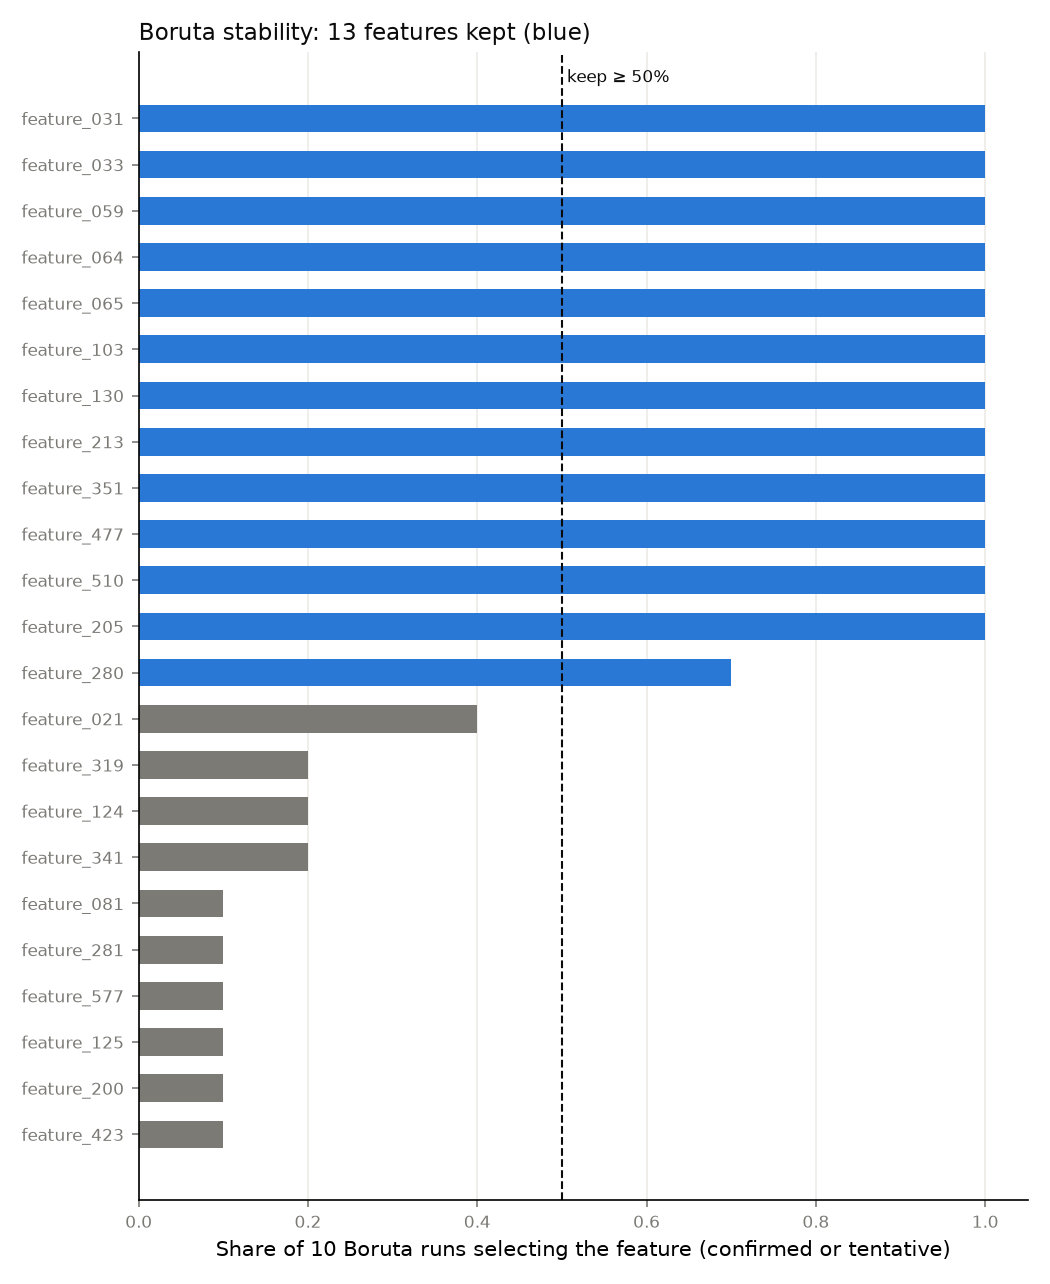

Kept: 13 features -> ['feature_031', 'feature_033', 'feature_059', 'feature_064', 'feature_065', 'feature_103', 'feature_130', 'feature_213', 'feature_351', 'feature_477', 'feature_510', 'feature_205', 'feature_280']


In [12]:
stability = pd.read_csv(REPORTS / "feature_selection" / "boruta_stability.csv", index_col=0)
display(stability.head(16))
display(Image(str(REPORTS / "feature_selection" / "boruta_stability.png"), width=820))
print(f"Kept: {int(stability['kept'].sum())} features -> {SELECTED}")

**Result: 450 → 13 features.** Eleven are confirmed in all 10 runs. Feature 205 is confirmed
in 8 and tentative in 2, and feature 280 is mostly tentative (1 confirmed + 6 tentative). The
next candidate, feature 021, appears in only 4 of 10 runs. The set sits just under the manual's
15–20 target. Lowering BorutaPy's acceptance percentile to 90 gives 76 features, so the 13 were
not forced into the target range by the settings.

**Overlap with other families (Document §7.3).** Each method's top 13 is compared with the
Boruta set:

In [13]:
ranks = pd.read_csv(REPORTS / "feature_selection" / "ranking_cross_check.csv", index_col=0)
n = len(SELECTED)
overlap = pd.DataFrame({
    "family": ["filter", "embedded"],
    f"in Boruta set (of top {n})": [
        int(ranks.loc[ranks["anova_rank"] <= n, "boruta_kept"].sum()),
        int(ranks.loc[ranks["rf_rank"] <= n, "boruta_kept"].sum())],
}, index=["ANOVA F-test", "RF impurity importance"])
display(overlap)
display(ranks.loc[SELECTED, ["anova_rank", "rf_rank"]].sort_values("rf_rank").T)

,family,in Boruta set (of top 13)
ANOVA F-test,filter,7
RF impurity importance,embedded,12


feature,feature_103,feature_059,feature_033,feature_031,feature_213,feature_477,feature_510,feature_351,feature_205,feature_130,feature_064,feature_065,feature_280
anova_rank,1,3,44,97,20,5,2,28,4,32,8,13,110
rf_rank,1,2,3,4,5,6,7,8,9,10,11,12,20


Random-forest importance agrees almost completely (12 of 13). The ANOVA filter agrees on only
7, and it ranks feature 033 at position 44. Part of the signal is non-linear or comes through
interactions, which a univariate linear filter cannot see. This supports a model-based method.

### 4.4 Choice of strategy and number of features (§7.4)

**Boruta** (wrapper) was chosen, with the filter and embedded rankings as cross-checks. Reasons:

- It is interpretable: every kept feature beat chance in a defined test.
- It captures interactions, which matter here (only 7/13 overlap with the filter).
- It is affordable at about 26 s per run.

`N_FEATURES` was not set in advance. It is the number of features that pass the stability
rule (13), and the cross-validation check in §4.6 tests it.

### 4.5 Leakage (§7.5)

The selector was fitted on **`X_train` and `y_train` only**. `X_test` and `y_test` were never
used. The 13-feature set above was chosen on all training rows, so a cross-validation score
that uses it is slightly optimistic. Inside the pipeline (§7), Boruta is therefore **refitted
within every fold**. Balancing (§6) comes after selection, so no synthetic row influences which
features are chosen.

### 4.6 Does the selected set perform? (§7.6)

The comparison uses repeated stratified 5-fold CV (3 repeats, identical folds) with a
class-weighted RF. The metric is PR-AUC, the area under the precision-recall curve. A
no-skill model scores 0.066 (the defect rate).

,n_features,pr_auc,pr_auc_sd,roc_auc,recall_at_fpr10
All 450 features,450.0,0.205,0.069,0.714,0.304
"Boruta 13, fixed on all training rows (manual §7.6)",13.0,0.224,0.063,0.727,0.320
Boruta refitted inside each fold (leakage-free),15.6,0.162,0.052,0.681,0.236


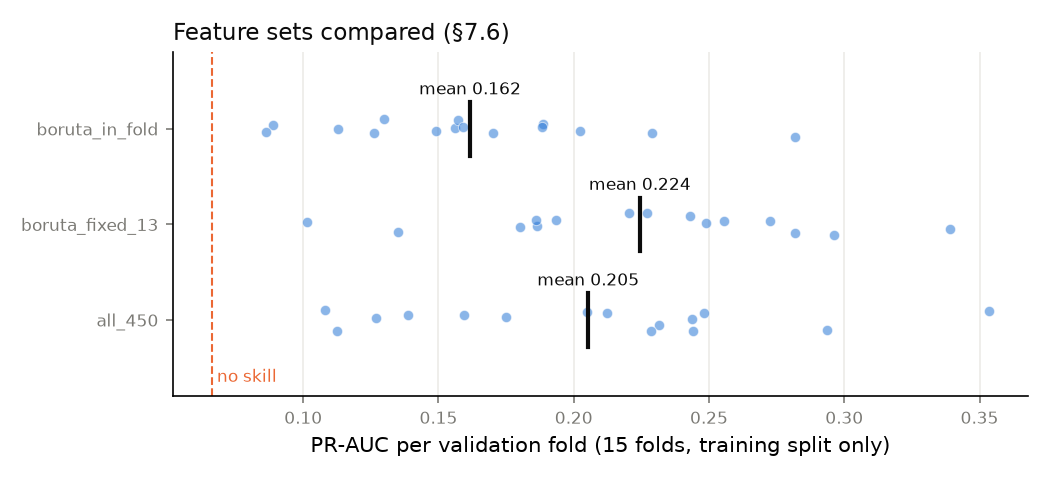

In [14]:
fs = pd.read_csv(REPORTS / "feature_selection" / "cv_summary.csv").set_index("variant")
fs.index = ["All 450 features", "Boruta 13, fixed on all training rows (manual §7.6)",
            "Boruta refitted inside each fold (leakage-free)"]
display(fs[["n_features", "pr_auc", "pr_auc_sd", "roc_auc", "recall_at_fpr10"]].round(3))
display(Image(str(REPORTS / "feature_selection" / "cv_feature_sets.png"), width=820))

**Interpretation (Document §7.6).** Measured the manual's way, the 13 features score slightly
**higher** than all 450 (0.224 vs 0.205, SD about 0.065, not significant). Measured honestly, with
Boruta refitted inside each fold, they score **lower** (0.162, worse in 13 of 15 folds). The
apparent gain is selection bias: the fixed set was chosen with the validation rows' labels.

The working explanation for the honest loss is that 83 defective wafers are few enough for
each fold's Boruta run to miss part of the weak signal spread across many sensors. This check
did not change the method. It did change two things for the grid search: Boruta is always
refitted inside each fold, and an "all features" option stays in the comparison (D-033).

In [15]:
display(sip_table([
    ("Filter: ANOVA F-test",
     "+ Fast, model-free.\n- Univariate and linear; misses interactions.",
     "Cross-check only", "7 of the top 13 in the Boruta set"),
    ("Embedded: RF impurity importance",
     "+ One fit, captures interactions.\n- Biased towards high-cardinality features; needs a "
     "cut-off.", "Cross-check only", "12 of the top 13 in the Boruta set"),
    ("Wrapper: Boruta (shadow features)",
     "+ Each feature tested against its own shuffled copy; all-relevant; interpretable.\n"
     "- Slower (about 26 s per run); seed-dependent -> 10 seeds.",
     "CHOSEN, tentative kept if selected in >= 50% of runs", "450 -> 13 features"),
    ("Number of features",
     "+ Manual target 15–20.\n- Padding to 15 would add features that pass in < 50% of runs.",
     "13 (data-driven)", "Honest in-fold PR-AUC 0.162 vs 0.205 for all 450 -> both kept for "
     "the grid search"),
]))

Options / approaches,Pro and con,Decision made,Consequence
Filter: ANOVA F-test,"+ Fast, model-free. - Univariate and linear; misses interactions.",Cross-check only,7 of the top 13 in the Boruta set
Embedded: RF impurity importance,"+ One fit, captures interactions. - Biased towards high-cardinality features; needs a cut-off.",Cross-check only,12 of the top 13 in the Boruta set
Wrapper: Boruta (shadow features),+ Each feature tested against its own shuffled copy; all-relevant; interpretable. - Slower (about 26 s per run); seed-dependent -> 10 seeds.,"CHOSEN, tentative kept if selected in >= 50% of runs",450 -> 13 features
Number of features,+ Manual target 15–20. - Padding to 15 would add features that pass in < 50% of runs.,13 (data-driven),Honest in-fold PR-AUC 0.162 vs 0.205 for all 450 -> both kept for the grid search


## 5. Normality check and min-max scaling (manual §8, week 5)

### 5.1 Which models, and do they need normal or scaled inputs? (§8.1)

The planned models are a **random forest** (main model) and a **logistic regression**
(comparison), with an SVM as an option. Trees split on thresholds and give the same result
under any monotone transformation, so they need neither normal nor scaled inputs. Logistic
regression and SVMs are sensitive to scale, and logistic regression works best when features
are not extremely skewed. The course asks for min-max scaling in every case, and it costs
nothing for the forest. The normality check is still documented:

All 450 imputed features: 445 reject normality (Shapiro-Wilk p < 0.05); 223 have |skew| > 1


,skew,kurtosis,shapiro_p,skew_yeo_johnson,shapiro_p_yeo_johnson
feature,,,,,
feature_031,1.155,-0.042,0.0,-0.291,0.000
feature_033,3.780,21.757,0.0,-0.083,0.000
feature_059,1.446,2.205,0.0,-0.308,0.000
feature_064,0.783,1.147,0.0,0.004,0.000
feature_065,0.882,1.695,0.0,0.016,0.000
feature_103,0.426,0.099,0.0,0.000,0.000
feature_130,-0.617,-0.229,0.0,-0.096,0.000
feature_213,1.030,2.139,0.0,0.021,0.000
feature_351,0.991,1.864,0.0,0.030,0.000


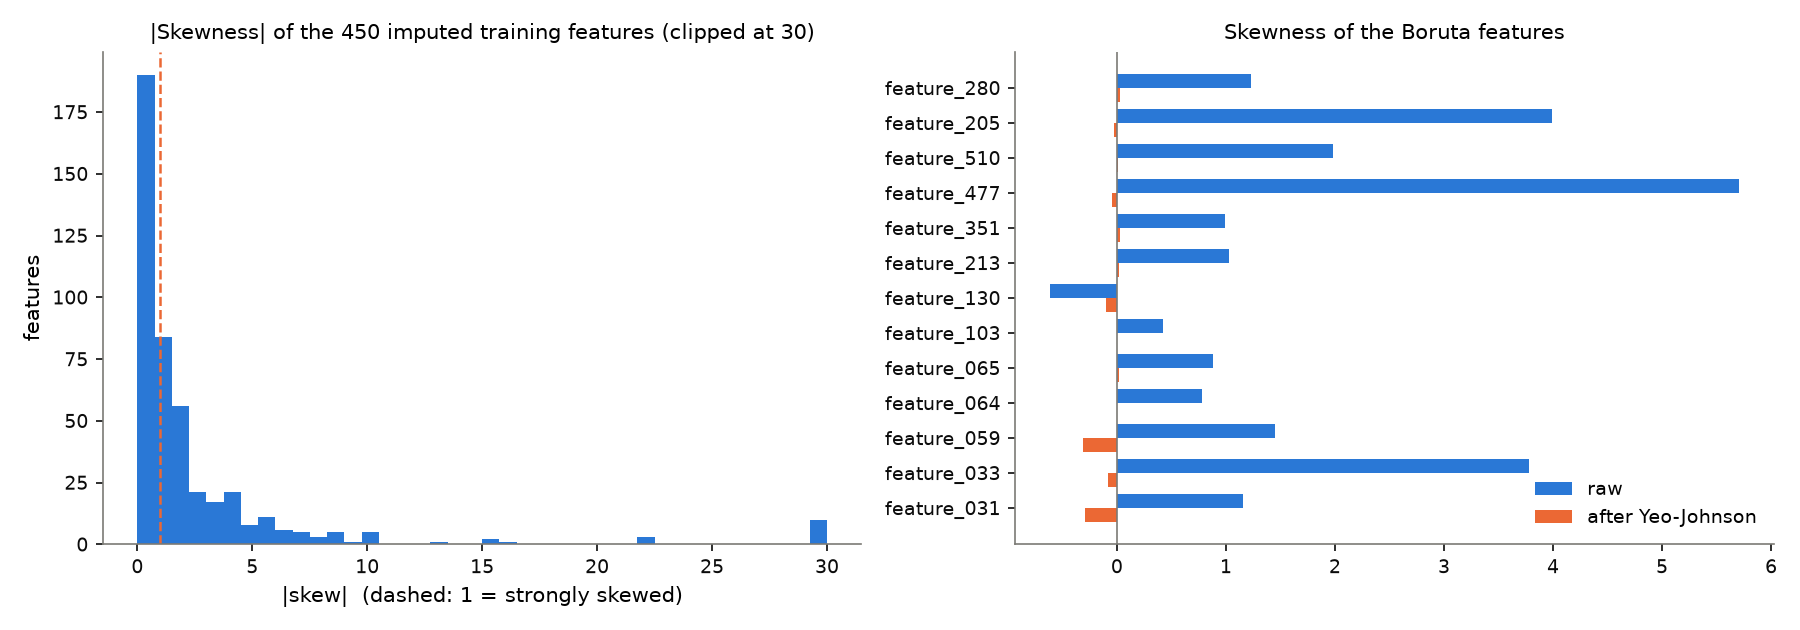

In [16]:
normal_all = pd.read_csv(REPORTS / "pipeline" / "normality_all_features.csv", index_col=0)
print(f"All 450 imputed features: {(normal_all['shapiro_p'] < 0.05).sum()} reject normality "
      f"(Shapiro-Wilk p < 0.05); {(normal_all['skew'].abs() > 1).sum()} have |skew| > 1")
normal_sel = normality_table(X_imp[SELECTED])
display(normal_sel.round(3))
display(Image(str(REPORTS / "pipeline" / "normality.png"), width=880))

Almost every feature is non-normal: 445 of 450 reject normality. Yeo-Johnson removes the skew of the 13
selected features (|skew| ≤ 0.31 afterwards), but Shapiro-Wilk still rejects all 13. With
1,253 wafers the test detects even small deviations. **Decision:** the random forest does not
assume normality, so no transformation is added to its pipeline. Yeo-Johnson stays an
option for the logistic regression in the model comparison.

### 5.2 Min-max scaling (§8.2–8.4)

Min-max maps each feature to [0, 1] with x' = (x − min) / (max − min), using the training
minimum and maximum. It is linear, so the shape of each distribution is unchanged.

Answers to the questions in §8.3:

- **Is scaling needed?** Not for the forest, but it is required by the course and needed for
  the logistic regression.
- **Outlier treatment.** Values were capped at 3σ, so no single extreme value stretches the
  range. Without capping, min-max would squeeze most wafers into a narrow band.
- **Skew.** Strong skew remains, and min-max does not change it.

The scaler is fitted on the training rows only. In the pipeline it is refitted within each
fold, **after** selection.

In [17]:
scaler = MinMaxScaler().set_output(transform="pandas").fit(X_imp[SELECTED])
X_scaled = scaler.transform(X_imp[SELECTED])
check = pd.DataFrame({"min": X_scaled.min(), "max": X_scaled.max(),
                      "skew before": X_imp[SELECTED].skew(), "skew after": X_scaled.skew()})
display(check.round(3).T)
print("Column names kept:", list(X_scaled.columns[:3]), "...  shape:", X_scaled.shape)

,feature_031,feature_033,feature_059,feature_064,feature_065,feature_103,feature_130,feature_213,feature_351,feature_477,feature_510,feature_205,feature_280
min,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
max,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
skew before,1.156,3.784,1.448,0.784,0.883,0.427,-0.618,1.032,0.992,5.715,1.981,3.999,1.236
skew after,1.156,3.784,1.448,0.784,0.883,0.427,-0.618,1.032,0.992,5.715,1.981,3.999,1.236


Column names kept: ['feature_031', 'feature_033', 'feature_059'] ...  shape: (1253, 13)


Every feature now spans exactly [0, 1] on the training rows, and the skewness is identical
before and after, as expected for a linear transformation. Test or validation wafers can fall
slightly outside [0, 1]. That is correct, because the scaler must not be refitted on them.

In [18]:
display(sip_table([
    ("No transform (normality)",
     "+ Forest is invariant to monotone transforms.\n- Logistic regression / SVM can suffer "
     "from skew.", "CHOSEN for the random forest", "445 / 450 features stay non-normal"),
    ("Yeo-Johnson",
     "+ Removes skew (|skew| <= 0.31 on the 13).\n- Still not normal (Shapiro); one more "
     "fitted step.", "Option for logistic regression", "-"),
    ("Min-max (0–1)",
     "+ Course's method; bounded; keeps shapes.\n- Sensitive to extremes (handled by the 3σ "
     "cap).", "CHOSEN, after Boruta", "13 features in [0, 1] on train; names kept"),
    ("Standardisation (z-score)",
     "+ Mean 0, SD 1.\n- Unbounded.", "Used only inside the k-NN imputer",
     "-"),
]))

Options / approaches,Pro and con,Decision made,Consequence
No transform (normality),+ Forest is invariant to monotone transforms. - Logistic regression / SVM can suffer from skew.,CHOSEN for the random forest,445 / 450 features stay non-normal
Yeo-Johnson,+ Removes skew (|skew| <= 0.31 on the 13). - Still not normal (Shapiro); one more fitted step.,Option for logistic regression,-
Min-max (0–1),+ Course's method; bounded; keeps shapes. - Sensitive to extremes (handled by the 3σ cap).,"CHOSEN, after Boruta","13 features in [0, 1] on train; names kept"
Standardisation (z-score),"+ Mean 0, SD 1. - Unbounded.",Used only inside the k-NN imputer,-


## 6. Class imbalance (manual §9, week 4)

### 6.1 The problem and the accuracy baseline (§9.1–9.2)

In [19]:
counts = y_train.value_counts().rename({0: "good", 1: "defective"})
display(pd.DataFrame({"wafers": counts, "share": (counts / len(y_train)).round(4)}))
print(f"Always predicting 'good' gives accuracy {1 - y_train.mean():.3f} with recall 0.")

,wafers,share
defective,,
good,1170,0.9338
defective,83,0.0662


Always predicting 'good' gives accuracy 0.934 with recall 0.


**Baseline accuracy: 0.934.** A model has to beat this, and accuracy cannot show whether it
does anything useful. The forest in §3 reached exactly this number while catching no defect. A
classifier minimises its overall error, and with 14 good wafers for every defective one, the
cheapest way to do that is to ignore the defective class.

### 6.2 Strategies (§9.3)

| Strategy | Changes the data? | Idea | Trade-off on SECOM (1,253 wafers, 83 defective) |
|---|---|---|---|
| Random undersampling | Yes, removes rows | Drop good wafers until balanced | Leaves 166 wafers, too few for 13 or more features |
| Random oversampling | Yes, adds copies | Repeat defective wafers | Exact copies invite overfitting |
| **ROSE** (smoothed bootstrap) | Yes, adds jittered copies | Resample defects and add small Gaussian noise | R package. Python equivalent: `RandomOverSampler(shrinkage=1.0)` |
| **SMOTE** | Yes, synthetic rows | Interpolate between a defect and one of its 5 nearest defect neighbours | Synthetic points can land in good-wafer regions if the classes overlap |
| **ADASYN** | Yes, synthetic rows | Like SMOTE, but more points near hard (mixed) regions | Can amplify noise |
| Class weights | No | Weight errors on defects 14× more in training | No new rows; weaker effect on random forests |

### 6.3 Is SMOTE sensible with 83 defects? (§9.4)

SMOTE interpolates between defective wafers and their nearest defective neighbours. If those
neighbours are actually closer to many good wafers, the synthetic points fall among good
wafers. The cell below measures this in the scaled 13-feature space.

In [20]:
from sklearn.neighbors import NearestNeighbors
values = X_scaled.to_numpy()
defect = y_train.to_numpy() == 1
nn = NearestNeighbors(n_neighbors=6).fit(values)
_, idx = nn.kneighbors(values[defect])
good_share = (~defect[idx[:, 1:]]).mean(axis=1)          # share of good wafers among 5 neighbours
print(f"Defective wafers whose 5 nearest neighbours are all good wafers: {(good_share == 1).mean():.0%}")
print(f"Median share of good wafers among a defect's 5 neighbours: {np.median(good_share):.0%}")
print(f"Undersampling would leave {2 * defect.sum()} of {len(defect):,} wafers.")

Defective wafers whose 5 nearest neighbours are all good wafers: 58%
Median share of good wafers among a defect's 5 neighbours: 100%
Undersampling would leave 166 of 1,253 wafers.


Most defective wafers are surrounded by good wafers, so the classes overlap strongly. SMOTE's
synthetic defects will partly land in regions dominated by good wafers. That is a reason to
test SMOTE against the alternatives instead of assuming it works. Undersampling would discard
about 87% of the data and is not considered further.

### 6.4 Applying the samplers: are the classes balanced? (§9.5)

In [21]:
display(resampling_counts(X_scaled, y_train).set_index("balancer").round(3))

,good,defective,rows,defect_share
balancer,,,,
none,1170,83,1253,0.066
class_weight,1170,83,1253,0.066
rose,1170,1170,2340,0.500
smote,1170,1170,2340,0.500
adasyn,1170,1187,2357,0.504


ROSE-style and SMOTE produce exactly 1,170 good and 1,170 defective rows. ADASYN produces
approximately balanced classes (1,187 defective), because it adapts the number of points per
neighbourhood. Samplers act **only on training rows during `fit`**. Validation and test wafers
are never resampled (§7).

### 6.5 Which balancer? (Document §9.4)

All options were compared in the full pipeline, with Boruta refitted in every fold, over 3×5-fold
CV at the default threshold of 0.5. Reproduce with `python -m secom_analysis.pipeline` (D-035).

In [22]:
bal = pd.read_csv(REPORTS / "pipeline" / "cv_summary.csv", index_col=0)
bal.index = bal.index.map(BALANCER_LABELS)
cols = ["sensitivity", "specificity", "precision", "f2", "roc_auc", "pr_auc", "cost"]
display(pd.DataFrame({c: bal[f"{c}_mean"].round(3).astype(str) + " ± "
                         + bal[f"{c}_sd"].round(3).astype(str) for c in cols}))

,sensitivity,specificity,precision,f2,roc_auc,pr_auc,cost
balancer,,,,,,,
None,0.008 ± 0.021,0.998 ± 0.003,0.089 ± 0.266,0.01 ± 0.025,0.675 ± 0.069,0.172 ± 0.049,6626.667 ± 205.171
Class weights,0.076 ± 0.048,0.975 ± 0.013,0.213 ± 0.142,0.086 ± 0.053,0.677 ± 0.064,0.159 ± 0.045,6720.0 ± 487.266
ROSE-style (smoothed bootstrap),0.289 ± 0.089,0.895 ± 0.026,0.166 ± 0.044,0.249 ± 0.069,0.697 ± 0.067,0.192 ± 0.062,7180.0 ± 722.298
SMOTE,0.145 ± 0.079,0.943 ± 0.025,0.157 ± 0.069,0.144 ± 0.073,0.692 ± 0.065,0.153 ± 0.036,7013.333 ± 627.77
ADASYN,0.145 ± 0.086,0.938 ± 0.025,0.144 ± 0.073,0.142 ± 0.08,0.688 ± 0.063,0.157 ± 0.038,7140.0 ± 737.564


- **Defects found:** ROSE-style finds the most (sensitivity 0.29, against 0.145 for SMOTE and
  ADASYN), and it has the highest PR-AUC (0.192).
- **Ranking quality:** almost the same for every option (ROC-AUC 0.675–0.697, fold SD about 0.065).
  The balancers mainly move the operating point, not the model's ability to rank wafers.
- **Class weights:** barely change a random forest at threshold 0.5.

**Decision:** SMOTE is the default, because the manual names it. ROSE-style, ADASYN, class
weights and no balancing remain options in the grid search. §8 shows that the decision
threshold matters more for cost than the choice of balancer.

In [23]:
display(sip_table([
    ("No balancing", "+ No synthetic data.\n- Model ignores defects.", "Baseline",
     "Sensitivity 0.008"),
    ("Class weights", "+ No new rows.\n- Weak effect for RF at threshold 0.5.",
     "Grid option", "Sensitivity 0.076"),
    ("ROSE-style (smoothed bootstrap)",
     "+ The manual's ROSE idea; simple.\n- Jitter can blur the class boundary.",
     "Grid option", "83 -> 1,170 defects in fit; sensitivity 0.289, PR-AUC 0.192"),
    ("SMOTE", "+ Manual's default; interpolates neighbours.\n- Classes overlap (6.3) -> some "
     "synthetic defects among good wafers.", "CHOSEN as default",
     "83 -> 1,170 defects in fit; sensitivity 0.145"),
    ("ADASYN", "+ Focuses on hard cases.\n- Amplifies noise in overlap regions.",
     "Grid option", "Sensitivity 0.145, slightly higher cost than SMOTE"),
    ("Undersampling", "+ No synthetic data.\n- Leaves 166 wafers.", "Rejected", "-"),
]))

Options / approaches,Pro and con,Decision made,Consequence
No balancing,+ No synthetic data. - Model ignores defects.,Baseline,Sensitivity 0.008
Class weights,+ No new rows. - Weak effect for RF at threshold 0.5.,Grid option,Sensitivity 0.076
ROSE-style (smoothed bootstrap),+ The manual's ROSE idea; simple. - Jitter can blur the class boundary.,Grid option,"83 -> 1,170 defects in fit; sensitivity 0.289, PR-AUC 0.192"
SMOTE,+ Manual's default; interpolates neighbours. - Classes overlap (6.3) -> some synthetic defects among good wafers.,CHOSEN as default,"83 -> 1,170 defects in fit; sensitivity 0.145"
ADASYN,+ Focuses on hard cases. - Amplifies noise in overlap regions.,Grid option,"Sensitivity 0.145, slightly higher cost than SMOTE"
Undersampling,+ No synthetic data. - Leaves 166 wafers.,Rejected,-


## 7. The machine-learning pipeline (manual §10)

### 7.1 Process map

Grey steps are fitted once, on the training split, and their stored results are reapplied to
new data (notebook 01). Blue steps sit inside the `imblearn` Pipeline and are refitted on whatever
training rows `fit()` receives, which in cross-validation is each fold's training part. The orange
step acts only during `fit`.

In [24]:
steps = [("Drop 116\nvariance = 0", MUTED), ("Drop 24\n> 60% missing", MUTED),
         ("3σ outliers\ncap | remove | none", BLUE), ("k-NN imputer\nk = 5, scaled", BLUE),
         ("Boruta\n(or all features)", BLUE), ("Min-max\n[0, 1]", BLUE),
         ("Balancer\nSMOTE | ROSE | …", ORANGE), ("Random forest\n500 trees", BLUE)]
fig, ax = plt.subplots(figsize=(13, 2.3))
for i, (label, color) in enumerate(steps):
    ax.add_patch(plt.Rectangle((i * 1.6, 0), 1.35, 1, color=color, alpha=0.9))
    ax.text(i * 1.6 + 0.675, 0.5, label, ha="center", va="center", color="white", fontsize=8.5)
    if i < len(steps) - 1:
        ax.annotate("", xy=(i * 1.6 + 1.58, 0.5), xytext=(i * 1.6 + 1.37, 0.5),
                    arrowprops=dict(arrowstyle="->", color=INK))
ax.text(0, 1.2, "fixed once on X_train (notebook 01)", color=MUTED, fontsize=9)
ax.text(3.2, 1.2, "imblearn Pipeline: refitted on every fit(X_train) / every CV fold "
        "(orange: fit only, skipped by predict)", color=BLUE, fontsize=9)
ax.set_xlim(-0.1, len(steps) * 1.6); ax.set_ylim(-0.1, 1.45); ax.axis("off")
plt.tight_layout(); plt.show()

The 3σ outlier step sits **inside** the pipeline, which differs from manual §10.2. The week-7
grid search varies the outlier treatment, so the step has to be part of the object being
searched over. Its bounds are still learned only from the training rows of each fit. The
column drops stay outside: they use no target information, and refitting them per fold would
change the feature space between folds.

### 7.2 The pipeline and its parameters (§10.3–10.4)

In [25]:
pipe = build_pipeline()          # defaults = the decisions of sections 2–6
display(pipe)
params = pd.DataFrame([
    ("outliers", "3σ rule, cap at mean ± 3·SD of the training rows", "notebook 01 §7, D-019"),
    ("imputer", "KNNImputer(n_neighbors=5, weights='distance') on standardised features", "§2, D-032"),
    ("selector", "BorutaPy(RF max_depth=5, class_weight='balanced', max_iter=100), tentative kept", "§4, D-033"),
    ("scaler", "MinMaxScaler, range [0, 1]", "§5, D-035"),
    ("balancer", "SMOTE(k_neighbors=5, random_state=42)", "§6, D-035"),
    ("model", "RandomForestClassifier(n_estimators=500, random_state=42)", "§3"),
], columns=["step", "exact parameters", "decided in"]).set_index("step")
display(params)

,steps,"[('outliers', ...), ('imputer', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,method,'cap'
,k,3.0
,n_neighbors,5
,seed,42
,max_iter,100
,keep_tentative,True
,"feature_range feature_range: tuple (min, max), default=(0, 1)Desired range of transformed data.","(0, ...)"


,exact parameters,decided in
step,,
outliers,"3σ rule, cap at mean ± 3·SD of the training rows","notebook 01 §7, D-019"
imputer,"KNNImputer(n_neighbors=5, weights='distance') ...","§2, D-032"
selector,"BorutaPy(RF max_depth=5, class_weight='balance...","§4, D-033"
scaler,"MinMaxScaler, range [0, 1]","§5, D-035"
balancer,"SMOTE(k_neighbors=5, random_state=42)","§6, D-035"
model,"RandomForestClassifier(n_estimators=500, rando...",§3


**Random states (Document §10.4).** One constant, `RANDOM_STATE = 42`, is used for:

- the train/test split (notebook 01);
- the cross-validation splitter;
- Boruta and its forest;
- the sampler;
- the random forest.

It is defined in `secom_analysis.impute` and imported by every module, so a teammate can find
and reuse it.

### 7.3 Testing the pipeline (§10.5)

The checks run on the first stratified CV fold. They produced the following results (reproduce
with `python -m secom_analysis.pipeline`):

In [26]:
checks = json.loads((REPORTS / "pipeline" / "pipeline_checks.json").read_text())
display(pd.DataFrame(checks["step_shapes_in_fit"], index=["rows", "columns"]))
for key in ["train_rows", "validation_rows", "rows_shared_between_train_and_validation",
            "rows_after_balancer_in_fit", "predictions_returned_for_validation",
            "identical_predictions_on_refit", "minmax_range_on_train", "test_set_sealed"]:
    print(f"{key:45s} {checks[key]}")

,input,outliers,imputer,selector,scaler,balancer
rows,1002,1002,1002,1002,1002,1872
columns,450,450,450,18,18,18


train_rows                                    1002
validation_rows                               251
rows_shared_between_train_and_validation      0
rows_after_balancer_in_fit                    1872
predictions_returned_for_validation           251
identical_predictions_on_refit                True
minmax_range_on_train                         [0.0, 1.0]
test_set_sealed                               True


**Document §10.5.** The shapes behave as Sections 4 and 6 predict:

- **Columns:** Boruta, refitted on this fold, keeps 18 features. That is within the 10–26
  range seen across folds, and close to the 13 chosen on all rows.
- **Rows:** SMOTE grows the fold's 1,002 training rows to 1,872 (936 good + 936 defective)
  during `fit`.
- **Predictions:** `predict` returns exactly one prediction for each of the 251 validation
  wafers.
- **Reproducibility:** the check returned True; refitting gives identical predictions.

### 7.4 Q&A: data flow and leakage (§10.6)

| Question | Answer |
|---|---|
| Why can a single `pipeline.fit(X_train, y_train)` be trusted not to leak test information? | Every step is fitted inside that one call on the rows passed in, and nothing else. Statistics such as 3σ bounds, neighbour sets, Boruta's selection, min-max ranges and synthetic rows all come from `X_train`. `predict` only applies the stored transformations. The discipline is built into the object, so there is no hand-written fit/transform step to forget. |
| Why do the column removals of Section 4 (and, in the manual, the outlier step of Section 5) sit outside the Pipeline? | They are fixed, target-free decisions made once on the training split. Refitting them per fold would change the feature space from fold to fold, and they cannot leak the target. In this project the outlier step was moved **inside** (7.1), because the grid search varies it. Its bounds still come only from training rows. |
| Why does SMOTE need `imblearn.pipeline.Pipeline`? | scikit-learn's Pipeline only knows steps that `transform` X. SMOTE changes **the number of rows and y** through `fit_resample`, which only the imblearn Pipeline calls, and only during `fit`. |
| What happens to the balancer step when `pipeline.predict(X_test)` is called? | It is **skipped**. The other steps apply their stored transformation to the test rows. The balancer only adds training rows during `fit`. Test wafers are never resampled or duplicated, so every test wafer receives exactly one prediction. |
| What goes wrong if `pipeline.fit()` is accidentally called on all of X and y? | Test wafers would shape every fitted step: their values would enter the 3σ bounds and the imputer's neighbour pool, their labels would influence Boruta and SMOTE (synthetic defects interpolated from test defects), and the forest would train on them. Test metrics would then be optimistic. It first becomes visible as a gap between test and CV performance that is suspiciously small (or test better than CV), and as test rows appearing in the training row count. The `rows_shared_between_train_and_validation` check would no longer be 0. |

## 8. Assessing the model (week 4, manual §13)

### 8.1 Definition of success, confusion matrix, Type I and Type II errors

**Success = identifying a faulty wafer.** The positive class is *defective* (1).

| | predicted good | predicted defective |
|---|---|---|
| **actually good** | **TN** (true negative): good wafer passed | **FP** (false positive) = **Type I error**: false alarm, a good wafer is held for extra inspection |
| **actually defective** | **FN** (false negative) = **Type II error**: a defective wafer is missed and moves on down the line | **TP** (true positive): defect caught |

A Type II error is the expensive one. The course prices it at **400** against **100** for a
false alarm (cost = 100·FP + 400·FN).

### 8.2 Metrics derived from the confusion matrix

| Metric | Formula | Meaning for SECOM |
|---|---|---|
| Accuracy | (TP + TN) / all | Share of correct calls; dominated by the 93% good wafers |
| Sensitivity (recall) | TP / (TP + FN) | Share of defective wafers caught. **Primary** |
| Specificity | TN / (TN + FP) | Share of good wafers passed |
| Precision | TP / (TP + FP) | Share of alarms that are real defects |
| F1 | 2·P·R / (P + R) | Balance of precision and recall |
| F2 | 5·P·R / (4P + R) | Like F1 but weights recall 4× more, which fits the cost ratio |
| ROC curve / AUC | sensitivity vs 1 − specificity over all thresholds | Ranking quality; 0.5 = random |
| PR curve / PR-AUC | precision vs recall over all thresholds | Ranking quality for the rare class; no-skill = 0.066 |

**Why accuracy is not a good measure.** The model that never raises an alarm scores 0.934 and
catches nothing (§3). For imbalanced data, sensitivity, precision, F2, PR-AUC and the
cost are the measures that matter.

### 8.3 Out-of-fold predictions of the full pipeline

Every training wafer is predicted once by a pipeline that never saw it. The CV is stratified
5-fold, and outliers, imputation and Boruta are refitted within each fold. The cell below
compares SMOTE (the default) and ROSE-style balancing.

In [27]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
oof = {name: np.zeros(len(y_train)) for name in ["smote", "rose"]}
for k, (tr, va) in enumerate(folds.split(X_train, y_train)):
    front = build_pipeline()[:3].fit(X_train.iloc[tr], y_train.iloc[tr])   # outliers, imputer, Boruta
    f_tr, f_va = front.transform(X_train.iloc[tr]), front.transform(X_train.iloc[va])
    for name in oof:
        back = build_pipeline(balancer=name)[3:].fit(f_tr, y_train.iloc[tr])
        oof[name][va] = back.predict_proba(f_va)[:, 1]
    print(f"fold {k + 1}: {f_tr.shape[1]} features selected")

metrics = pd.DataFrame({BALANCER_LABELS[n]: error_metrics(y_train, p) for n, p in oof.items()}).T
display(metrics[["TP", "FN", "FP", "TN", "accuracy", "sensitivity", "specificity",
                 "precision", "f1", "f2", "roc_auc", "pr_auc", "cost"]].round(3))
print(f"Always-pass reference: accuracy {1 - y_train.mean():.3f}, cost {COST_FN * int(y_train.sum()):,}")

fold 1: 18 features selected


fold 2: 15 features selected


fold 3: 12 features selected


fold 4: 26 features selected


/home/bnam/Desktop/Warehouse/SECOM/.venv/lib/python3.12/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bnam/Desktop/Warehouse/SECOM/.venv/lib/python3.12/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bnam/Desktop/Warehouse/SECOM/.venv/lib/python3.12/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bnam/Desktop/

/home/bnam/Desktop/Warehouse/SECOM/.venv/lib/python3.12/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bnam/Desktop/Warehouse/SECOM/.venv/lib/python3.12/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bnam/Desktop/Warehouse/SECOM/.venv/lib/python3.12/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bnam/Desktop/

... (39 outputs left out)

/home/bnam/Desktop/Warehouse/SECOM/.venv/lib/python3.12/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bnam/Desktop/Warehouse/SECOM/.venv/lib/python3.12/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bnam/Desktop/Warehouse/SECOM/.venv/lib/python3.12/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/bnam/Desktop/

fold 5: 14 features selected


,TP,FN,FP,TN,accuracy,sensitivity,specificity,precision,f1,f2,roc_auc,pr_auc,cost
SMOTE,12.0,71.0,50.0,1120.0,0.903,0.145,0.957,0.194,0.166,0.152,0.686,0.149,33400.0
ROSE-style (smoothed bootstrap),24.0,59.0,113.0,1057.0,0.863,0.289,0.903,0.175,0.218,0.256,0.695,0.180,34900.0


Always-pass reference: accuracy 0.934, cost 33,200


In [28]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for (name, proba), color in zip(oof.items(), [BLUE, ORANGE]):
    label = BALANCER_LABELS[name]
    fpr, tpr, _ = roc_curve(y_train, proba)
    axes[0].plot(fpr, tpr, color=color, label=f"{label} (AUC {roc_auc_score(y_train, proba):.3f})")
    prec, rec, _ = precision_recall_curve(y_train, proba)
    axes[1].plot(rec, prec, color=color,
                 label=f"{label} (PR-AUC {average_precision_score(y_train, proba):.3f})")
axes[0].plot([0, 1], [0, 1], color=MUTED, ls="--", lw=1)
axes[0].set(xlabel="1 − specificity (false-alarm rate)", ylabel="sensitivity", title="ROC curve")
axes[1].axhline(y_train.mean(), color=MUTED, ls="--", lw=1)
axes[1].set(xlabel="recall (sensitivity)", ylabel="precision", title="Precision-recall curve")
thresholds = np.linspace(0.02, 0.9, 89)
proba = oof["smote"]
rec_t = [((proba >= t) & (y_train == 1)).sum() / y_train.sum() for t in thresholds]
prec_t = [((proba >= t) & (y_train == 1)).sum() / max((proba >= t).sum(), 1) for t in thresholds]
cost_t = [error_metrics(y_train, proba, t)["cost"] for t in thresholds]
axes[2].plot(thresholds, rec_t, color=BLUE, label="sensitivity")
axes[2].plot(thresholds, prec_t, color=ORANGE, label="precision")
axes[2].axvline(0.5, color=MUTED, ls="--", lw=1)
ax2 = axes[2].twinx()
ax2.plot(thresholds, np.array(cost_t) / 1000, color=INK, lw=1, label="cost (k)")
ax2.axhline(COST_FN * y_train.sum() / 1000, color=INK, ls=":", lw=1)
ax2.set_ylabel("cost, thousands (dotted: always pass)")
axes[2].set(xlabel="decision threshold", title="SMOTE: trade-off vs threshold")
for ax in axes[:2]:
    ax.legend(frameon=False, fontsize=8)
axes[2].legend(frameon=False, fontsize=8, loc="upper center")
plt.tight_layout(); plt.show()

/tmp/ipykernel_2795/2561776844.py:29: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.show()


**Reading the results.**

- **At the default threshold of 0.5, both pipelines cost more than always-pass.** Each extra
  defect caught costs several false alarms. ROC-AUC is about 0.69, which means the model ranks
  defective wafers above good ones clearly better than chance, but far from perfectly.
- **The precision–sensitivity trade-off (week 4).** Lowering the threshold flags more wafers.
  Sensitivity rises because more defects are caught, but precision falls because most of the extra
  alarms are good wafers (right panel). Both cannot be maximised at once. On overlapping classes
  (§6.3), any threshold that catches more defects also catches more good wafers. The cost
  combines the two errors into one number. With costs of 100/400, the expected-cost threshold
  for calibrated probabilities is 100 / (100 + 400) = 0.2.
- **Next step (phase K).** The threshold is chosen later, on cross-validated predictions like
  these and never on the test set, together with the grid search.

## 9. Training error vs validation error and model complexity (week 5)

The **training error** is the error on the rows the model was fitted on, and shows how well it
learned them. The **validation (test) error** is the error on rows it has never seen, and
shows how well it generalises. The cell below varies one complexity knob, the forest's
maximum tree depth, and measures both errors in stratified 5-fold CV. The error measure is
1 − balanced accuracy, so the majority class cannot hide errors.

To keep the run short, the 13 features fixed on all training rows are used (slightly
optimistic, §4.6). Outlier capping, imputation, scaling and SMOTE are refitted per fold.

In [29]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import balanced_accuracy_score
depths = [1, 2, 3, 4, 6, 8, 12, None]
rows = []
for tr, va in folds.split(X_train, y_train):
    prep = build_pipeline(selector="all")[:2].fit(X_train.iloc[tr])          # outliers + imputer
    a_tr = prep.transform(X_train.iloc[tr])[SELECTED]
    a_va = prep.transform(X_train.iloc[va])[SELECTED]
    sc = MinMaxScaler().fit(a_tr)
    a_tr, a_va = sc.transform(a_tr), sc.transform(a_va)
    a_bal, y_bal = make_balancer("smote").fit_resample(a_tr, y_train.iloc[tr])
    for d in depths:
        rf = RandomForestClassifier(n_estimators=200, max_depth=d, n_jobs=-1,
                                    random_state=RANDOM_STATE).fit(a_bal, y_bal)
        rows.append({"max_depth": "None" if d is None else str(d),
                     "training error": 1 - balanced_accuracy_score(y_train.iloc[tr], rf.predict(a_tr)),
                     "validation error": 1 - balanced_accuracy_score(y_train.iloc[va], rf.predict(a_va))})
curve = pd.DataFrame(rows).groupby("max_depth", sort=False).mean()
curve["gap"] = curve["validation error"] - curve["training error"]
display(curve.round(3).T)
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(curve.index, curve["training error"], "o-", color=BLUE, label="training error")
ax.plot(curve.index, curve["validation error"], "o-", color=ORANGE, label="validation error (CV)")
ax.set(xlabel="max tree depth (complexity →)", ylabel="1 − balanced accuracy",
       title="Training vs validation error, random forest + SMOTE")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

max_depth,1,2,3,4,6,8,12,None
training error,0.276,0.246,0.220,0.174,0.101,0.059,0.019,0.000
validation error,0.330,0.340,0.332,0.334,0.314,0.360,0.427,0.439
gap,0.054,0.093,0.112,0.160,0.213,0.301,0.408,0.439


/tmp/ipykernel_2795/3681836150.py:26: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  ax.legend(frameon=False); plt.tight_layout(); plt.show()


**Gap and complexity.** Shallow forests make similar errors on training and validation rows:
they are too simple to fit either well, but the gap is small. As depth grows, the training error
falls towards zero because the trees memorise the training wafers, including SMOTE's synthetic
points. The validation error does not follow, so **the gap widens with complexity**. This is the
classic pattern: more complex models fit the training data better but generalise no better,
or worse. The training confusion matrix of a fully grown forest (§3: 83 / 83 defects found) is
therefore meaningless as a quality estimate. Depth and the other forest parameters are tuned
in the grid search.

## 10. Summary, state, and open points

| Step | Decision | Effect on the training split |
|---|---|---|
| Duplicates (§1) | Checked on X_train | 0 duplicates; 450 columns |
| Missing values (§2) | k-NN, k = 5, standardised; fitted on train only | 11,211 → 0 missing cells |
| First model (§3) | Default RF | Training accuracy 1.000 vs CV 0.934 (recall 0) |
| Feature selection (§4) | Boruta, 10 seeds, tentative kept at ≥ 50% | 450 → 13 features |
| Normality / scaling (§5) | No transform for RF; min-max after Boruta | 13 features in [0, 1] |
| Imbalance (§6) | SMOTE default; ROSE-style, ADASYN, class weights as grid options | 83 → 1,170 defects in each fit |
| Pipeline (§7) | `imblearn` Pipeline; outliers, imputer, Boruta, scaler, balancer, RF refitted per fit | Checks pass; reproducible |
| First assessment (§8) | Confusion matrix, metrics, ROC / PR curves on out-of-fold predictions | At threshold 0.5 no option beats always-pass on cost |

**Open points**

1. **Grid search (phase J):** outlier treatment × k × selector (Boruta / all) × balancer × forest
   parameters, scored by cross-validation.
2. **Threshold (phase K):** chosen on cross-validated predictions with cost 100·FP + 400·FN
   (about 0.2 if calibrated).
3. **Test set:** the manual's week-5 steps 5–7 apply the pipeline to the test set at this stage.
   In this project the test set is used **once**, for the final model (phase L), so that no
   choice in phases J–K is tuned to it. The training-vs-test comparison the manual asks for
   (week 5, step 7) is made then. See the open item in the diary.